In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure display options
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Load the dataset
df = pd.read_csv('train.csv')

print("--- Initial Inspection ---")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")
print("\nMissing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])





--- Initial Inspection ---
Total Rows: 384873, Total Columns: 14

Missing values per column:
deliveryDate    31614
color             116
dateOfBirth     39193
dtype: int64


In [2]:
df.head(2)

,id,orderDate,deliveryDate,itemID,size,color,manufacturerID,price,customerID,salutation,dateOfBirth,state,creationDate,returnShipment
0,1,2012-10-10,2012-11-05,2244,m,grey,33,59.9,2367,Mrs,1943-10-14,Baden-Wuerttemberg,2012-04-03,0
1,2,2013-03-15,NaN,2806,37,stained,1,189.9,82758,Mrs,1967-08-07,Bavaria,2013-03-15,0


In [3]:
df.tail(2)

,id,orderDate,deliveryDate,itemID,size,color,manufacturerID,price,customerID,salutation,dateOfBirth,state,creationDate,returnShipment
384871,384872,2012-08-01,2012-08-02,1599,xl,ocher,75,279.9,3392,Mrs,1964-09-17,North Rhine-Westphalia,2011-09-23,1
384872,384873,2012-07-01,2012-07-03,323,39,petrol,70,69.9,26762,Mrs,1969-03-15,North Rhine-Westphalia,2011-02-16,1


In [4]:
print("\n--- Info Summary ---")
df.describe
df.info


--- Info Summary ---


<bound method DataFrame.info of             id   orderDate deliveryDate  itemID     size    color  \
0            1  2012-10-10   2012-11-05    2244        m     grey   
1            2  2013-03-15          NaN    2806       37  stained   
2            3  2012-04-23   2012-05-03     263        m    ocher   
3            4  2012-07-10   2012-08-02     488       39    black   
4            5  2012-07-22   2012-07-24    1403       44    black   
...        ...         ...          ...     ...      ...      ...   
384868  384869  2012-10-21   2012-11-05    1505  unsized    berry   
384869  384870  2013-01-26   2013-01-29    2878       XL      red   
384870  384871  2012-07-11   2012-07-17     843        s   silver   
384871  384872  2012-08-01   2012-08-02    1599       xl    ocher   
384872  384873  2012-07-01   2012-07-03     323       39   petrol   

        manufacturerID   price  customerID salutation dateOfBirth  \
0                   33   59.90        2367        Mrs  1943-10-14   
1

In [5]:
# Check missing value counts and percentages
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percent (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
print("Columns with Missing Values:")
display(missing[missing['Missing_Count'] > 0])

# Numerical statistics
print("\n--- Numerical Summary ---")
display(df.describe().T)

# Categorical statistics
print("\n--- Categorical Summary ---")
display(df.describe(include=['O']).T)

Columns with Missing Values:


,Missing_Count,Missing_Percent (%)
deliveryDate,31614,8.21
color,116,0.03
dateOfBirth,39193,10.18



--- Numerical Summary ---


,count,mean,std,min,25%,50%,75%,max
id,384873.0,192437.000000,111103.409414,1.0,96219.0,192437.0,288655.0,384873.0
itemID,384873.0,1399.685247,931.038846,1.0,331.0,1569.0,2342.0,3071.0
manufacturerID,384873.0,29.714916,30.053290,1.0,5.0,21.0,43.0,166.0
price,384873.0,70.371017,45.472107,0.0,34.9,59.9,89.9,999.0
customerID,384873.0,33405.812203,23976.531215,6.0,12916.0,28472.0,51196.0,86611.0
returnShipment,384873.0,0.482780,0.499704,0.0,0.0,0.0,1.0,1.0



--- Categorical Summary ---


,count,unique,top,freq
orderDate,384873,365,2012-06-27,4473
deliveryDate,353259,326,2013-04-04,4227
size,384873,122,l,29874
color,384757,87,black,68829
salutation,384873,5,Mrs,369400
dateOfBirth,345680,14087,1900-11-19,3218
state,384873,16,North Rhine-Westphalia,88942
creationDate,384873,775,2011-02-16,113193


In [6]:
# 2. Date Parsing
date_cols = ['orderDate', 'deliveryDate', 'dateOfBirth', 'creationDate']
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')

In [7]:
# 3. Feature Engineering from Dates
# Calculate delivery duration in days
df['delivery_duration'] = (df['deliveryDate'] - df['orderDate']).dt.days

In [8]:
# Delivery missing flag (items canceled or delayed indefinitely)
df['is_delivery_missing'] = df['deliveryDate'].isnull().astype(int)

In [9]:
# Customer age at order time (filter placeholder birthdates like year <= 1920)
df['customer_age'] = (df['orderDate'] - df['dateOfBirth']).dt.days // 365.25
df.loc[(df['customer_age'] < 14) | (df['customer_age'] > 95), 'customer_age'] = np.nan

In [10]:
# Account age in days when the order was placed
df['account_age_days'] = (df['orderDate'] - df['creationDate']).dt.days

In [11]:
# Order time features
df['order_month'] = df['orderDate'].dt.month
df['order_day_of_week'] = df['orderDate'].dt.day_name()

In [12]:
# 4. Handle Categorical Standardization
df['color'] = df['color'].fillna('unknown').astype(str).str.lower().str.strip()
df['size'] = df['size'].astype(str).str.lower().str.strip()
print("\n--- Processed Dataset Sample ---")
print(df[['orderDate', 'delivery_duration', 'customer_age', 'price', 'returnShipment']].head())


--- Processed Dataset Sample ---
   orderDate  delivery_duration  customer_age  price  returnShipment
0 2012-10-10               26.0          68.0   59.9               0
1 2013-03-15                NaN          45.0  189.9               0
2 2012-04-23               10.0          31.0   69.9               1
3 2012-07-10               23.0           NaN  119.9               0
4 2012-07-22                2.0          50.0  159.9               0


C:\Users\ankur\AppData\Local\Temp\ipykernel_21884\614665237.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='returnShipment', data=df, palette='Set2', ax=axes[0])
C:\Users\ankur\AppData\Local\Temp\ipykernel_21884\614665237.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Kept (0)', 'Returned (1)'])
C:\Users\ankur\AppData\Local\Temp\ipykernel_21884\614665237.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='price_bin', y='returnShipment', data=price_return, palette='Blues_r', ax=axes[1])


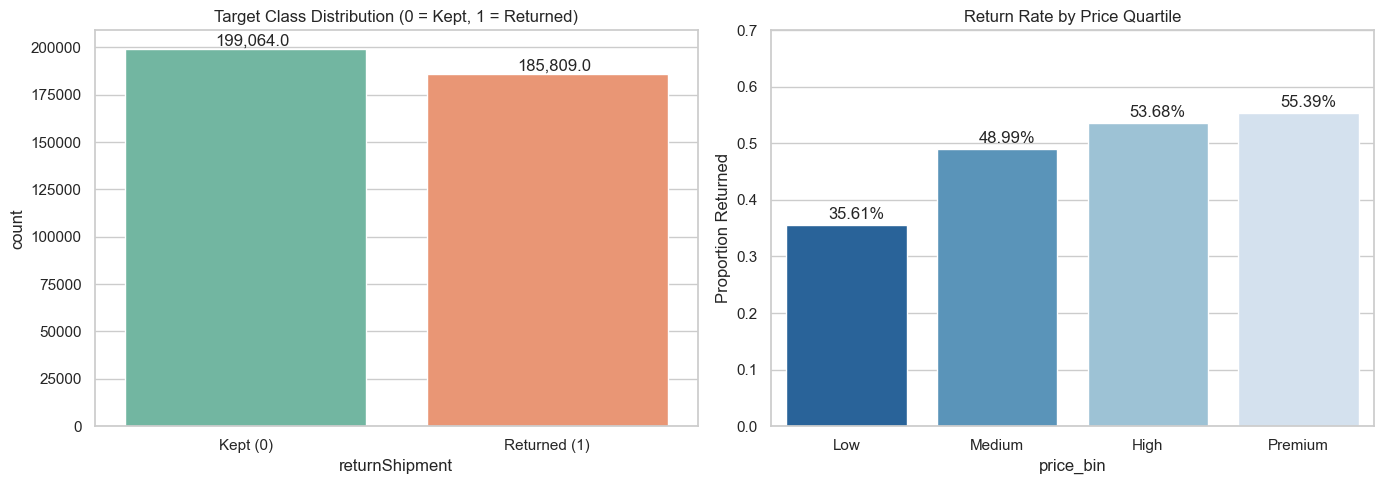

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Target Class Distribution
sns.countplot(x='returnShipment', data=df, palette='Set2', ax=axes[0])
axes[0].set_title('Target Class Distribution (0 = Kept, 1 = Returned)')
axes[0].set_xticklabels(['Kept (0)', 'Returned (1)'])
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():,}', (p.get_x() + 0.3, p.get_height() + 2000))

# Price segmentation vs Return Probability
df['price_bin'] = pd.qcut(df['price'], q=4, labels=['Low', 'Medium', 'High', 'Premium'])
price_return = df.groupby('price_bin', observed=False)['returnShipment'].mean().reset_index()

sns.barplot(x='price_bin', y='returnShipment', data=price_return, palette='Blues_r', ax=axes[1])
axes[1].set_title('Return Rate by Price Quartile')
axes[1].set_ylabel('Proportion Returned')
axes[1].set_ylim(0, 0.7)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.2%}", (p.get_x() + 0.28, p.get_height() + 0.01))

plt.tight_layout()
plt.show()

C:\Users\ankur\AppData\Local\Temp\ipykernel_21884\217126360.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='returnShipment', y='color', data=color_return, palette='viridis', ax=axes[0])
C:\Users\ankur\AppData\Local\Temp\ipykernel_21884\217126360.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='returnShipment', y='state', data=state_return, palette='mako', ax=axes[1])


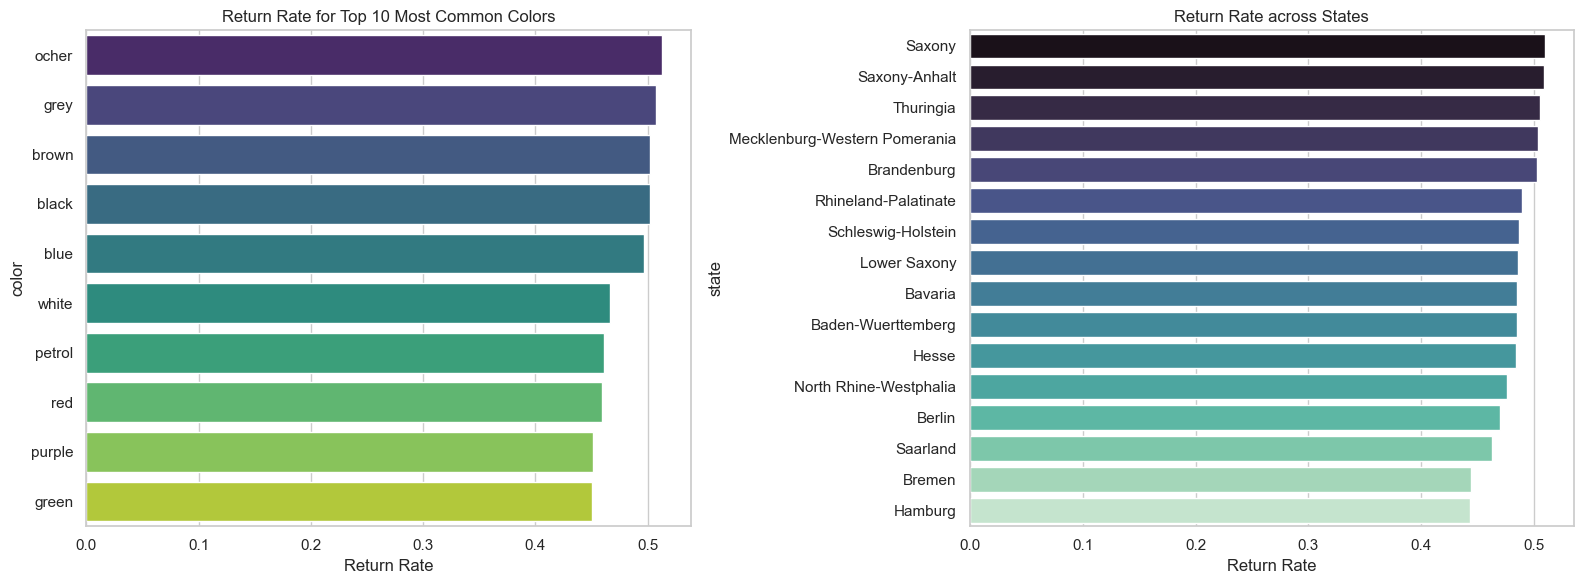

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10 most frequent colors and their return rates
top_colors = df['color'].value_counts().head(10).index
color_return = df[df['color'].isin(top_colors)].groupby('color')['returnShipment'].mean().sort_values(ascending=False).reset_index()

sns.barplot(x='returnShipment', y='color', data=color_return, palette='viridis', ax=axes[0])
axes[0].set_title('Return Rate for Top 10 Most Common Colors')
axes[0].set_xlabel('Return Rate')

# Return rate by German Federal State
state_return = df.groupby('state')['returnShipment'].mean().sort_values(ascending=False).reset_index()

sns.barplot(x='returnShipment', y='state', data=state_return, palette='mako', ax=axes[1])
axes[1].set_title('Return Rate across States')
axes[1].set_xlabel('Return Rate')

plt.tight_layout()
plt.show()

C:\Users\ankur\AppData\Local\Temp\ipykernel_21884\2954293372.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


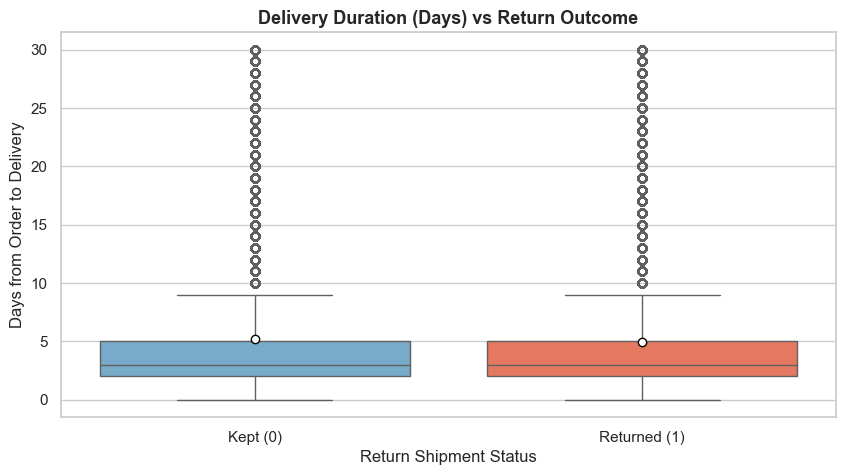

Median Delivery Days by Class:
returnShipment
0    3.0
1    3.0
Name: delivery_duration, dtype: float64


In [18]:
# Filter realistic delivery intervals (0 to 30 days) to eliminate negative/extreme outliers
valid_delivery = df[(df['delivery_duration'] >= 0) & (df['delivery_duration'] <= 30)]

plt.figure(figsize=(10, 5))
sns.boxplot(
    x='returnShipment', 
    y='delivery_duration', 
    data=valid_delivery, 
    palette=['#6baed6', '#fb6a4a'],
    showmeans=True,
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black"}
)
plt.title('Delivery Duration (Days) vs Return Outcome', fontsize=13, weight='bold')
plt.xticks([0, 1], ['Kept (0)', 'Returned (1)'])
plt.ylabel('Days from Order to Delivery')
plt.xlabel('Return Shipment Status')
plt.show()

# Quantify the difference
print("Median Delivery Days by Class:")
print(valid_delivery.groupby('returnShipment')['delivery_duration'].median())

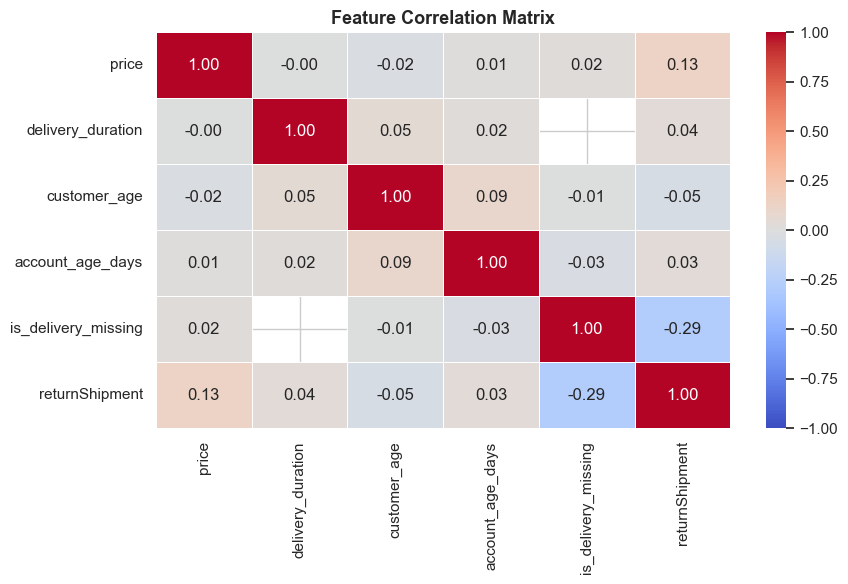

In [19]:
plt.figure(figsize=(9, 6))

numeric_cols = [
    'price', 
    'delivery_duration', 
    'customer_age', 
    'account_age_days', 
    'is_delivery_missing', 
    'returnShipment'
]

corr_matrix = df[numeric_cols].corr()

sns.heatmap(
    corr_matrix, 
    annot=True, 
    cmap='coolwarm', 
    fmt='.2f', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5
)
plt.title('Feature Correlation Matrix', fontsize=13, weight='bold')
plt.tight_layout()
plt.show()

In [20]:
# Check if the customer ordered multiple sizes of the same item on the exact same date
same_item_sizes = df.groupby(['customerID', 'orderDate', 'itemID'])['size'].transform('nunique')
df['is_bracketed'] = (same_item_sizes > 1).astype(int)

# Compare return rates for bracketed vs non-bracketed orders
bracket_rates = df.groupby('is_bracketed')['returnShipment'].agg(
    order_count='count', 
    return_rate='mean'
).reset_index()

bracket_rates['is_bracketed'] = bracket_rates['is_bracketed'].map({0: 'Single Size Ordered', 1: 'Multiple Sizes (Bracketed)'})
display(bracket_rates)

,is_bracketed,order_count,return_rate
0,Single Size Ordered,330428,0.456889
1,Multiple Sizes (Bracketed),54445,0.639912


In [21]:
# 1. Flag bracketing: customer ordering the same item in multiple sizes on the same date
same_item_sizes = df.groupby(['customerID', 'orderDate', 'itemID'])['size'].transform('nunique')
df['is_bracketed'] = (same_item_sizes > 1).astype(int)

# 2. Flag unsized items: accessories, bags, or non-fitted apparel
df['is_unsized'] = df['size'].str.lower().str.contains('unsized').astype(int)

print("Engineered behavioral features:")
print(f"Bracketed orders rate: {df['is_bracketed'].mean():.2%}")
print(f"Unsized products rate: {df['is_unsized'].mean():.2%}")

Engineered behavioral features:
Bracketed orders rate: 14.15%
Unsized products rate: 5.41%


In [22]:
from sklearn.model_selection import train_test_split

# Define feature sets
# Drop raw identifier columns and raw date strings that are not suitable for direct tabular modeling
features_to_drop = [
    'id', 'customerID', 'itemID', 'orderDate', 
    'deliveryDate', 'dateOfBirth', 'creationDate', 
    'returnShipment', 'price_tier'
]

# Separate features (X) and target (y)
X = df.drop(columns=[col for col in features_to_drop if col in df.columns])
y = df['returnShipment']

print(f"Features matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")
print(f"Selected Features: {list(X.columns)}")

# Stratified split to preserve class balance (80% train, 20% validation)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"\nTrain set: {X_train.shape[0]:,} samples")
print(f"Validation set: {X_val.shape[0]:,} samples")
print(f"Train target balance: {y_train.mean():.4f}")
print(f"Validation target balance: {y_val.mean():.4f}")

Features matrix shape: (384873, 15)
Target vector shape: (384873,)
Selected Features: ['size', 'color', 'manufacturerID', 'price', 'salutation', 'state', 'delivery_duration', 'is_delivery_missing', 'customer_age', 'account_age_days', 'order_month', 'order_day_of_week', 'price_bin', 'is_bracketed', 'is_unsized']

Train set: 307,898 samples
Validation set: 76,975 samples
Train target balance: 0.4828
Validation target balance: 0.4828


In [23]:
# Check if the customer ordered multiple sizes of the same item on the exact same date
same_item_sizes = df.groupby(['customerID', 'orderDate', 'itemID'])['size'].transform('nunique')
df['is_bracketed'] = (same_item_sizes > 1).astype(int)

# Compare return rates for bracketed vs non-bracketed orders
bracket_rates = df.groupby('is_bracketed')['returnShipment'].agg(
    order_count='count', 
    return_rate='mean'
).reset_index()

bracket_rates['is_bracketed'] = bracket_rates['is_bracketed'].map({0: 'Single Size Ordered', 1: 'Multiple Sizes (Bracketed)'})
display(bracket_rates)

,is_bracketed,order_count,return_rate
0,Single Size Ordered,330428,0.456889
1,Multiple Sizes (Bracketed),54445,0.639912


C:\Users\ankur\AppData\Local\Temp\ipykernel_21884\2193858096.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='is_unsized', y='returnShipment', data=df, palette='Blues_r', ax=ax)
C:\Users\ankur\AppData\Local\Temp\ipykernel_21884\2193858096.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Fitted/Sized Product', 'Unsized/Accessory'])


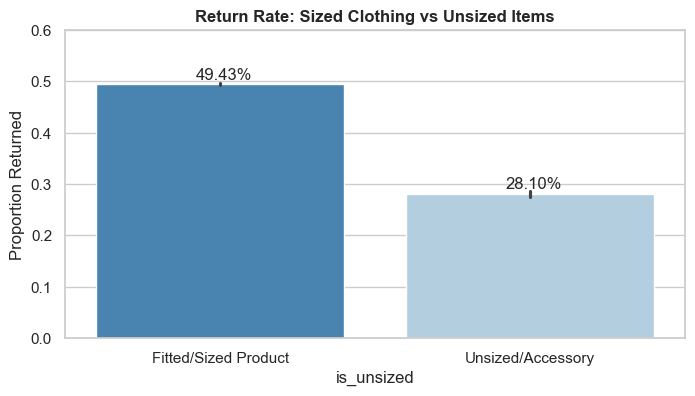

In [24]:
# Flag whether an item is unsized/free-size vs tailored fit
df['is_unsized'] = df['size'].str.lower().str.contains('unsized').astype(int)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x='is_unsized', y='returnShipment', data=df, palette='Blues_r', ax=ax)
ax.set_title('Return Rate: Sized Clothing vs Unsized Items', fontsize=12, weight='bold')
ax.set_xticklabels(['Fitted/Sized Product', 'Unsized/Accessory'])
ax.set_ylabel('Proportion Returned')
ax.set_ylim(0, 0.6)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2%}", (p.get_x() + 0.32, p.get_height() + 0.01))
plt.show()

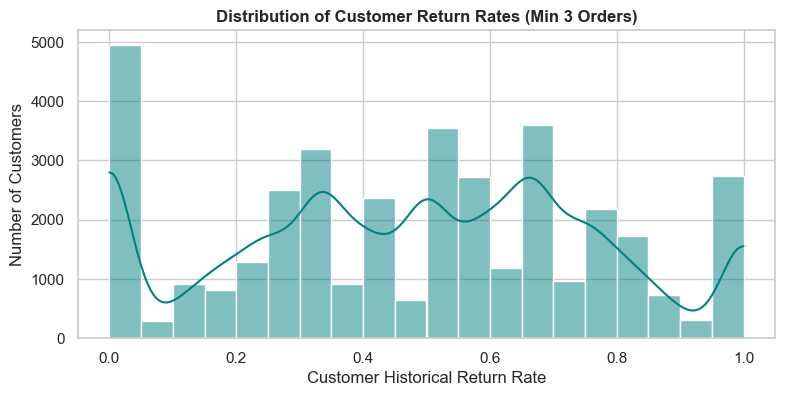

In [25]:
# Compute historical return rate per customer (using out-of-fold/expanding window logic to prevent leakage)
customer_stats = df.groupby('customerID')['returnShipment'].agg(
    total_orders='count',
    total_returns='sum'
).reset_index()

customer_stats['customer_return_rate'] = customer_stats['total_returns'] / customer_stats['total_orders']

plt.figure(figsize=(9, 4))
sns.histplot(customer_stats[customer_stats['total_orders'] >= 3]['customer_return_rate'], bins=20, kde=True, color='teal')
plt.title('Distribution of Customer Return Rates (Min 3 Orders)', fontsize=12, weight='bold')
plt.xlabel('Customer Historical Return Rate')
plt.ylabel('Number of Customers')
plt.show()

C:\Users\ankur\AppData\Local\Temp\ipykernel_21884\2156378958.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='manufacturerID', y='return_rate', data=mfg_df, order=mfg_df['manufacturerID'], palette='magma')


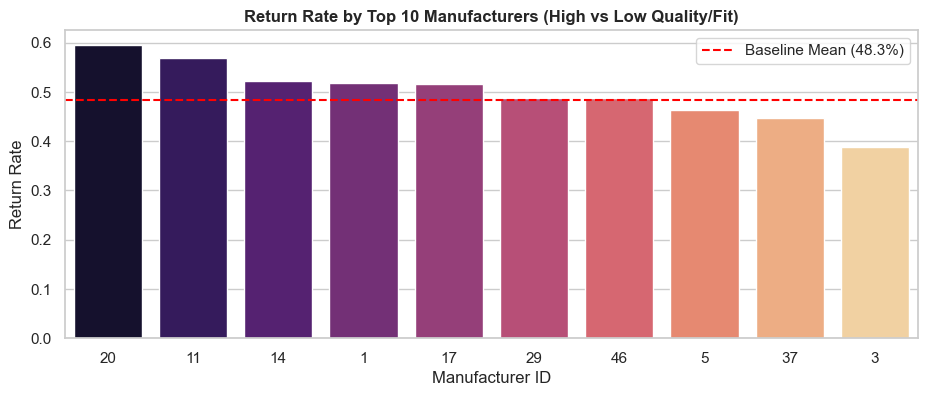

In [26]:
top_10_mfg = df['manufacturerID'].value_counts().head(10).index
mfg_df = df[df['manufacturerID'].isin(top_10_mfg)].groupby('manufacturerID')['returnShipment'].agg(
    order_count='count',
    return_rate='mean'
).reset_index().sort_values('return_rate', ascending=False)

plt.figure(figsize=(11, 4))
sns.barplot(x='manufacturerID', y='return_rate', data=mfg_df, order=mfg_df['manufacturerID'], palette='magma')
plt.axhline(df['returnShipment'].mean(), color='red', linestyle='--', label=f'Baseline Mean ({df["returnShipment"].mean():.1%})')
plt.title('Return Rate by Top 10 Manufacturers (High vs Low Quality/Fit)', fontsize=12, weight='bold')
plt.xlabel('Manufacturer ID')
plt.ylabel('Return Rate')
plt.legend()
plt.show()